# Student Dropout and Academic Performance Prediction Using Machine Learning
**Complete implementation: Preprocessing, EDA, Modelling, Evaluation and Prediction**

Name: Aditya Agrawal  |  Roll No: S25CSEU0694

**Dataset:** Predict Students' Dropout and Academic Success (UCI / Kaggle), about 4,424 students and 36 features.
**Goal:** predict whether a student will be a *Dropout*, *Enrolled* or *Graduate*.

**Steps in this notebook:** 1) Load data, 2) Data understanding, 3) Data cleaning checks, 4) Exploratory Data Analysis, 5) Preprocessing (encoding, scaling, train/test split), 6) Model training, 7) Evaluation, 8) Prediction demo.

In [2]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)

## 1. Load the dataset
Upload `dataset.csv` to Colab (folder icon on the left, then the upload icon) before running this cell.

In [3]:
import os
if not os.path.exists('dataset.csv'):
    try:
        from google.colab import files
        print('Please choose dataset.csv')
        files.upload()
    except ImportError:
        pass

# sep=None lets pandas detect whether the file uses commas or semicolons
data = pd.read_csv('dataset.csv', sep=None, engine='python')
data.columns = data.columns.str.strip()
data = data.rename(columns={'Nacionality': 'Nationality'})
print('Shape:', data.shape)
data.head()

Shape: (4424, 35)


,﻿Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,10,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,10,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Data understanding

In [4]:
print('Rows:', data.shape[0], '| Columns:', data.shape[1])
print()
data.info()

Rows: 4424 | Columns: 35

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   ﻿Marital status                                 4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nationality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupa

In [5]:
# Statistical summary of the numeric columns
data.describe().T

,count,mean,std,min,25%,50%,75%,max
﻿Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,6.886980,5.298964,1.00,1.00,8.000000,12.000000,18.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,9.899186,4.331792,1.00,6.00,10.000000,13.000000,17.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,2.531420,3.963707,1.00,1.00,1.000000,1.000000,17.000000
Nationality,4424.0,1.254521,1.748447,1.00,1.00,1.000000,1.000000,21.000000
Mother's qualification,4424.0,12.322107,9.026251,1.00,2.00,13.000000,22.000000,29.000000
Father's qualification,4424.0,16.455244,11.044800,1.00,3.00,14.000000,27.000000,34.000000
Mother's occupation,4424.0,7.317812,3.997828,1.00,5.00,6.000000,10.000000,32.000000


## 3. Data cleaning checks

In [6]:
print('Total missing values :', data.isnull().sum().sum())
print('Duplicate rows           :', data.duplicated().sum())
print('Target classes           :', list(data['Target'].unique()))

Total missing values : 0
Duplicate rows           : 0
Target classes           : ['Dropout', 'Graduate', 'Enrolled']


_Observation: write here whether any missing values or duplicates were found (the dataset is usually already clean)._

## 4. Exploratory Data Analysis

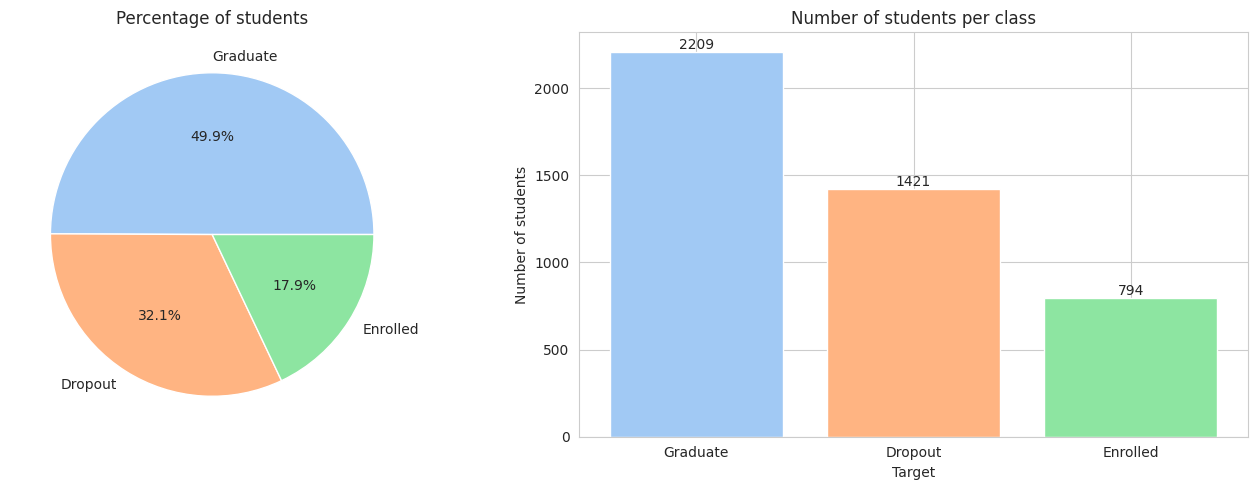

In [7]:
# 4.1 Target distribution
counts = data['Target'].value_counts()
colors = sns.color_palette('pastel')[:len(counts)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.pie(counts.values, labels=counts.index, autopct='%.1f%%', colors=colors)
ax1.set_title('Percentage of students')

bars = ax2.bar(counts.index, counts.values, color=colors)
ax2.set_xlabel('Target')
ax2.set_ylabel('Number of students')
ax2.set_title('Number of students per class')
for b in bars:
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height(), int(b.get_height()),
             ha='center', va='bottom')
plt.tight_layout()
plt.show()

_Observation: Graduate is the largest class and Enrolled the smallest, so the classes are imbalanced. This matters when we choose evaluation metrics (F1-score, not only accuracy)._

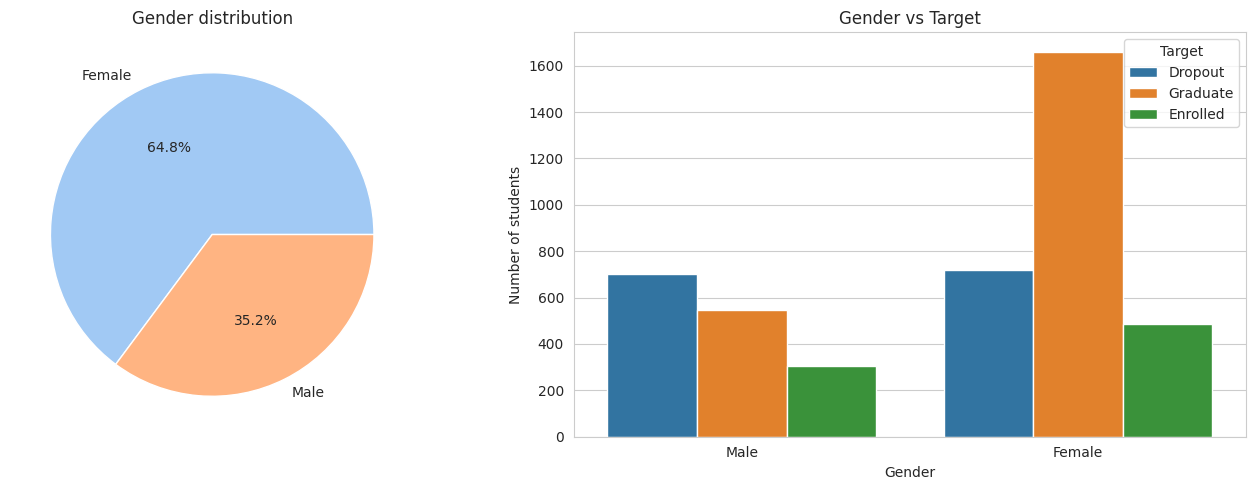

In [8]:
# 4.2 Gender distribution and gender vs target
gender_names = {0: 'Female', 1: 'Male'}
g = data['Gender'].map(gender_names).value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.pie(g.values, labels=g.index, autopct='%.1f%%', colors=sns.color_palette('pastel')[:len(g)])
ax1.set_title('Gender distribution')

plot_df = data.assign(Gender=data['Gender'].map(gender_names))
sns.countplot(data=plot_df, x='Gender', hue='Target', ax=ax2)
ax2.set_title('Gender vs Target')
ax2.set_ylabel('Number of students')
plt.tight_layout()
plt.show()

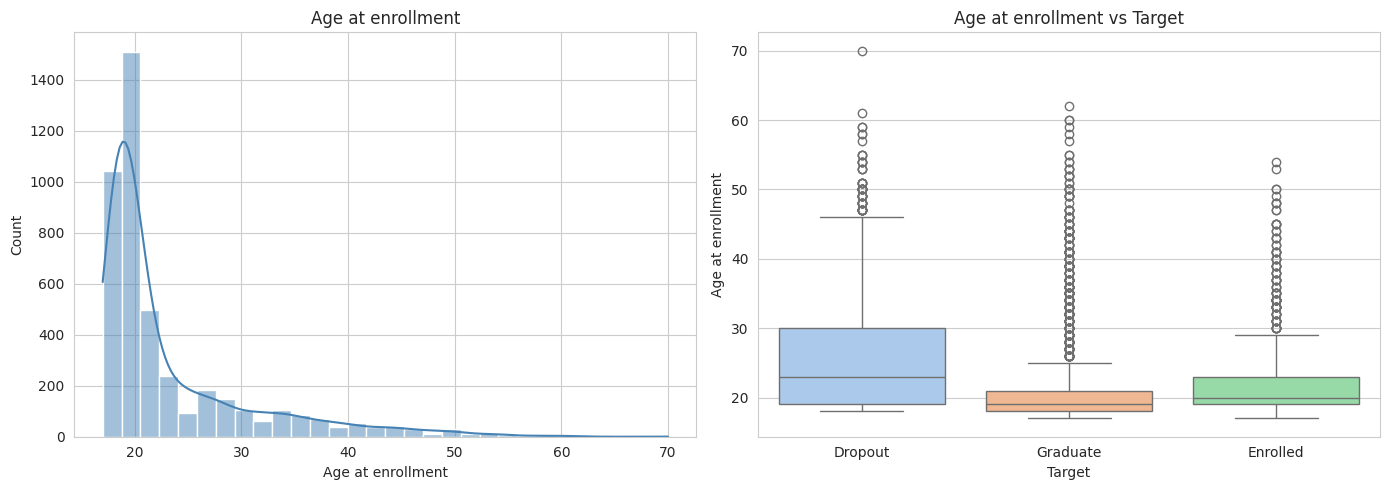

In [9]:
# 4.3 Age at enrollment and target
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data['Age at enrollment'], bins=30, kde=True, ax=ax1, color='steelblue')
ax1.set_title('Age at enrollment')

sns.boxplot(data=data, x='Target', y='Age at enrollment', ax=ax2, palette='pastel', hue='Target', legend=False)
ax2.set_title('Age at enrollment vs Target')
plt.tight_layout()
plt.show()

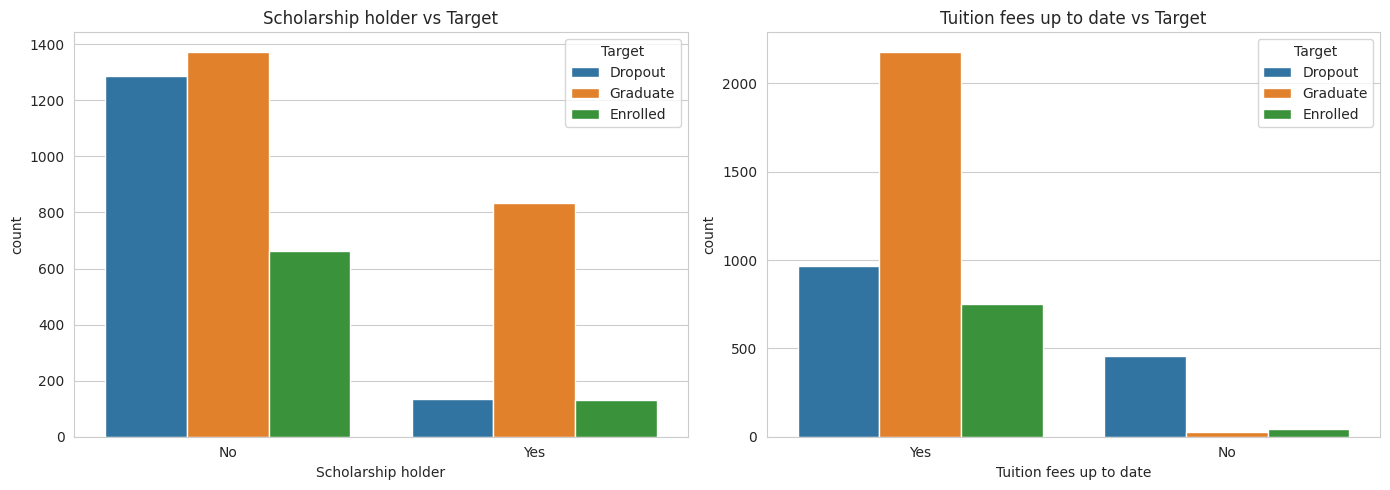

In [10]:
# 4.4 Scholarship holder and tuition fees up to date vs target
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=data.assign(**{'Scholarship holder': data['Scholarship holder'].map({0: 'No', 1: 'Yes'})}),
              x='Scholarship holder', hue='Target', ax=ax1)
ax1.set_title('Scholarship holder vs Target')

sns.countplot(data=data.assign(**{'Tuition fees up to date': data['Tuition fees up to date'].map({0: 'No', 1: 'Yes'})}),
              x='Tuition fees up to date', hue='Target', ax=ax2)
ax2.set_title('Tuition fees up to date vs Target')
plt.tight_layout()
plt.show()

Using columns: ['Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)']


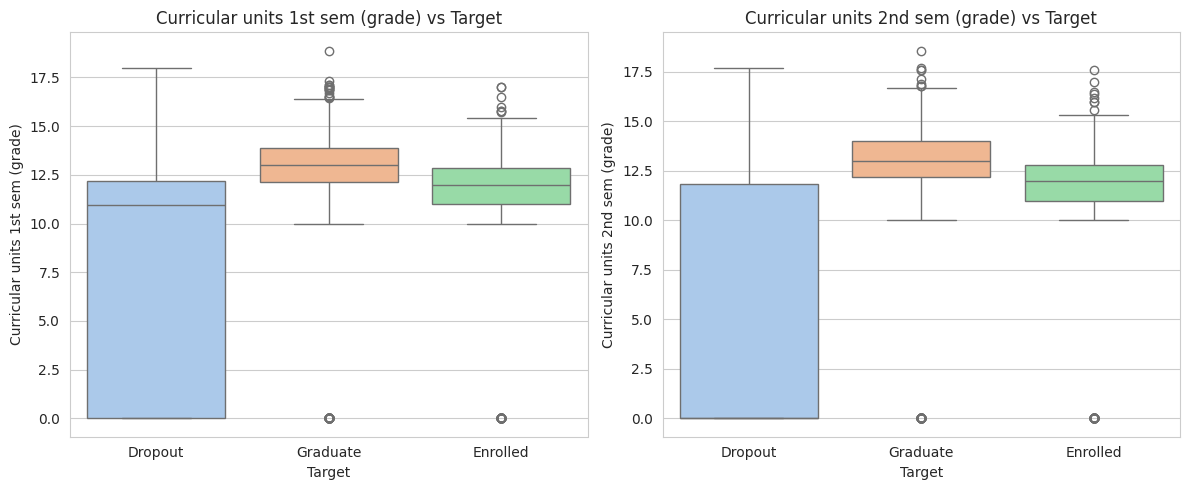

In [11]:
# 4.5 Academic performance vs target
grade_cols = [c for c in data.columns if 'grade' in c.lower()][:3]
print('Using columns:', grade_cols)

fig, axes = plt.subplots(1, len(grade_cols), figsize=(6 * len(grade_cols), 5))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, grade_cols):
    sns.boxplot(data=data, x='Target', y=c, ax=ax, palette='pastel', hue='Target', legend=False)
    ax.set_title(c + ' vs Target')
plt.tight_layout()
plt.show()

_Observation: students who graduate tend to have higher first and second semester grades and more approved units, while dropouts have lower grades. Write what you see in your own words._

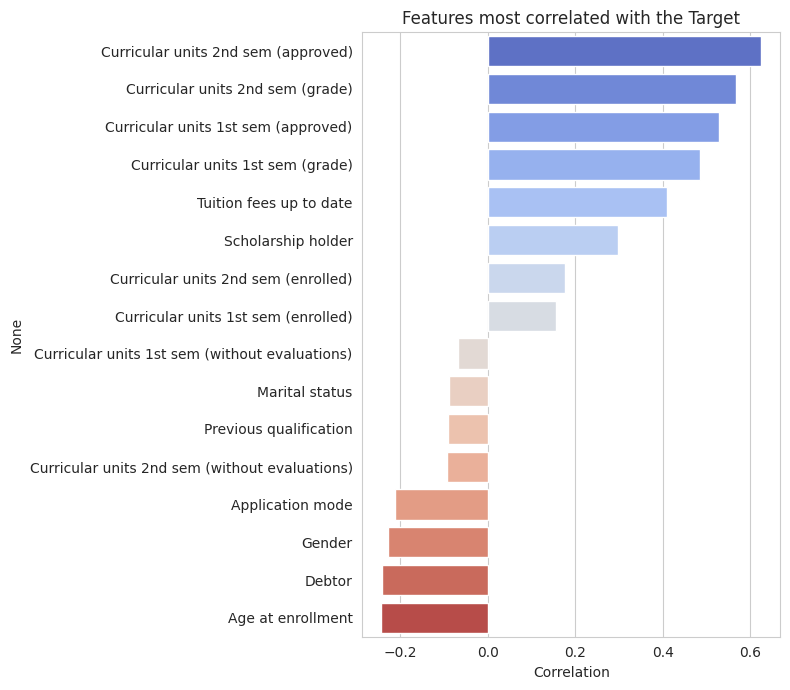

In [12]:
# 4.6 Correlation of every feature with the target
# Temporary numeric version of the target (Dropout=0, Enrolled=1, Graduate=2), used only for this plot
target_num = data['Target'].map({'Dropout': 0, 'Enrolled': 1, 'Graduate': 2})
corr = data.drop(columns='Target').corrwith(target_num).sort_values(ascending=False)

top = pd.concat([corr.head(8), corr.tail(8)])
plt.figure(figsize=(8, 7))
sns.barplot(x=top.values, y=top.index, palette='coolwarm', hue=top.index, legend=False)
plt.title('Features most correlated with the Target')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

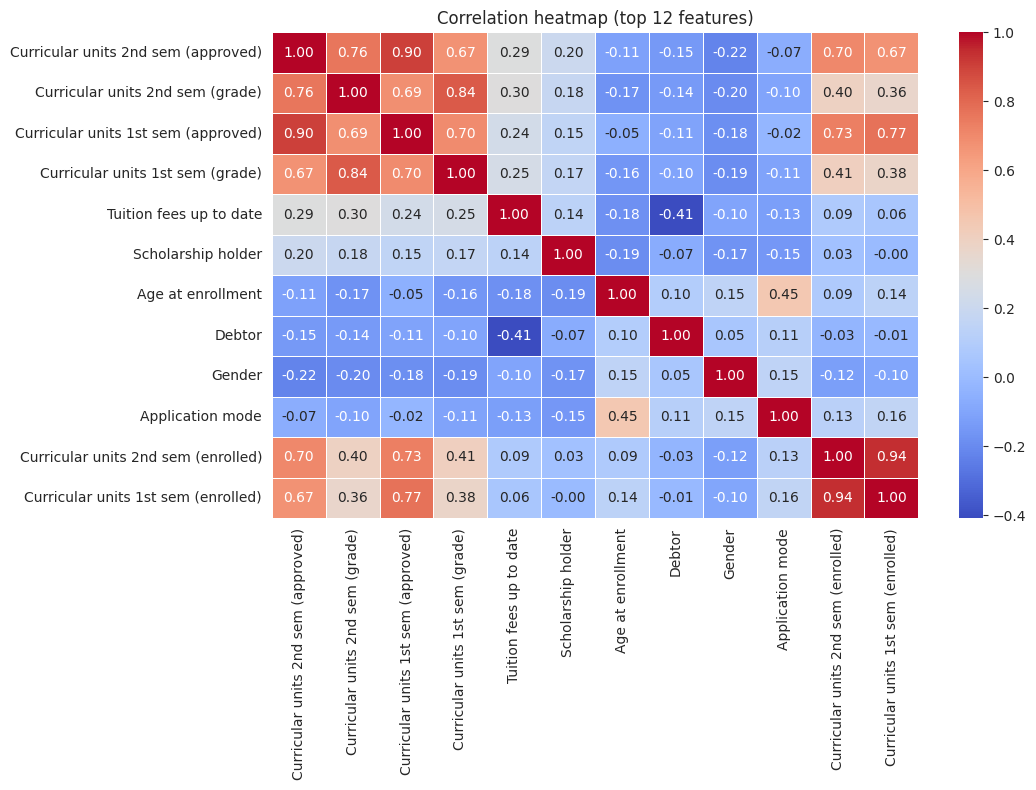

In [13]:
# 4.7 Correlation heatmap of the most important features
important = list(corr.abs().sort_values(ascending=False).head(12).index)
plt.figure(figsize=(11, 8))
sns.heatmap(data[important].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation heatmap (top 12 features)')
plt.tight_layout()
plt.show()

_Observation: the 1st and 2nd semester approved units and grades are the features most linked to the outcome. They are also strongly correlated with each other, which is expected._

## 5. Data preprocessing

In [14]:
# 5.1 Remove duplicates (if any) and separate features / target
data = data.drop_duplicates().reset_index(drop=True)

X = data.drop(columns='Target')
y_text = data['Target']
print('Features shape:', X.shape)

# Make sure every feature is numeric (the dataset already stores categories as codes)
print('Non-numeric columns:', list(X.select_dtypes(exclude='number').columns))

Features shape: (4424, 34)
Non-numeric columns: []


In [15]:
# 5.2 Encode the target: Dropout / Enrolled / Graduate -> 0 / 1 / 2
le = LabelEncoder()
y = le.fit_transform(y_text)
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}


In [16]:
# 5.3 Train / test split (80% / 20%); stratify keeps the class ratios the same in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train class counts:', np.bincount(y_train))
print('Test class counts :', np.bincount(y_test))

Train: (3539, 34) | Test: (885, 34)
Train class counts: [1137  635 1767]
Test class counts : [284 159 442]


In [17]:
# 5.4 Feature scaling (fit on the training data only, to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Mean of scaled train features (should be ~0):', round(float(X_train_scaled.mean()), 4))
print('Std  of scaled train features (should be ~1):', round(float(X_train_scaled.std()), 4))

Mean of scaled train features (should be ~0): 0.0
Std  of scaled train features (should be ~1): 1.0


## 6. Model training and comparison
Three models taught in the course: Logistic Regression (baseline), Decision Tree and Random Forest.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    results.append([name, accuracy_score(y_test, pred), f1_score(y_test, pred, average='weighted')])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'F1 (weighted)']).round(3)
results_df

,Model,Accuracy,F1 (weighted)
0,Logistic Regression,0.758,0.743
1,Decision Tree,0.686,0.689
2,Random Forest,0.780,0.766


Best model: Random Forest


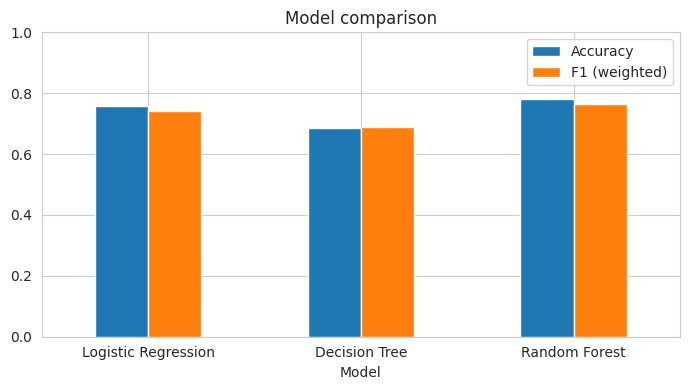

In [19]:
# Pick the best model by weighted F1-score
best_name = results_df.sort_values('F1 (weighted)', ascending=False).iloc[0]['Model']
best = models[best_name]
print('Best model:', best_name)

plt.figure(figsize=(7, 4))
results_df.set_index('Model')[['Accuracy', 'F1 (weighted)']].plot(kind='bar', rot=0, ax=plt.gca())
plt.ylim(0, 1); plt.title('Model comparison'); plt.tight_layout(); plt.show()

## 7. Evaluation of the best model

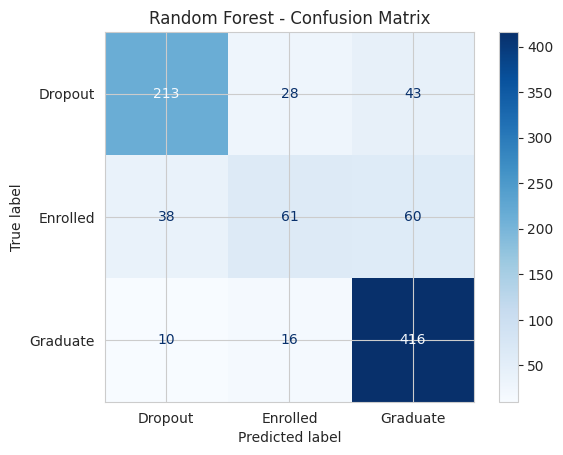

              precision    recall  f1-score   support

     Dropout       0.82      0.75      0.78       284
    Enrolled       0.58      0.38      0.46       159
    Graduate       0.80      0.94      0.87       442

    accuracy                           0.78       885
   macro avg       0.73      0.69      0.70       885
weighted avg       0.77      0.78      0.77       885



In [20]:
pred = best.predict(X_test_scaled)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=le.classes_).plot(cmap='Blues')
plt.title(best_name + ' - Confusion Matrix')
plt.show()
print(classification_report(y_test, pred, target_names=le.classes_))

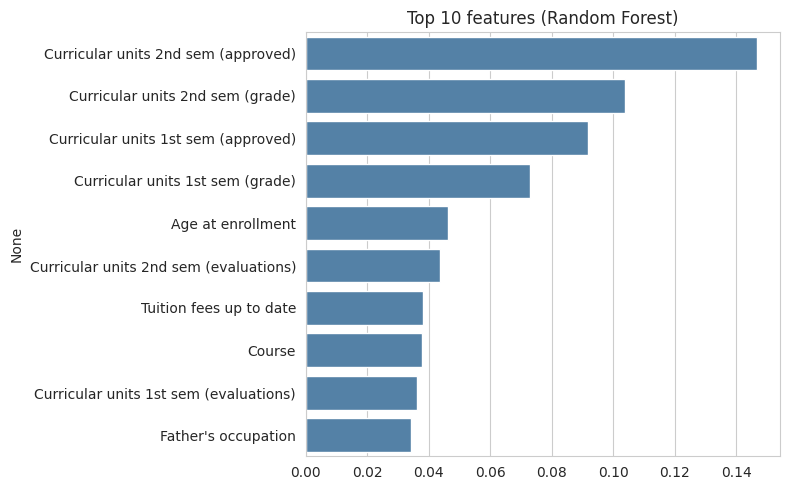

In [21]:
# Feature importance (available for Decision Tree / Random Forest)
tree_model = models['Random Forest']
imp = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title('Top 10 features (Random Forest)')
plt.tight_layout()
plt.show()

## 8. Prediction demo

In [22]:
# Predict for one student from the test set
i = 5   # change this number to try another student
student_scaled = scaler.transform(X_test.iloc[[i]])
probs = best.predict_proba(student_scaled)[0]

print('Predicted :', le.inverse_transform([best.predict(student_scaled)[0]])[0])
print('Actual    :', le.inverse_transform([y_test[i]])[0])
for label, p in zip(le.classes_, probs):
    print(f'  {label}: {p*100:.1f}%')

Predicted : Enrolled
Actual    : Graduate
  Dropout: 25.0%
  Enrolled: 40.0%
  Graduate: 35.0%


In [23]:
# Predict for a new student: start from an average student and change a few values
def predict_student(changes):
    row = X.median().to_frame().T
    for col, val in changes.items():
        if col in row.columns:
            row[col] = val
    p = best.predict_proba(scaler.transform(row))[0]
    print('Prediction:', le.inverse_transform(best.predict(scaler.transform(row)))[0])
    for label, v in zip(le.classes_, p):
        print(f'  {label}: {v*100:.1f}%')

approved = [c for c in X.columns if 'approved' in c.lower()]

print('High-risk student (no approved subjects):')
predict_student({c: 0 for c in approved})
print()
print('Strong student (6 approved subjects per semester):')
predict_student({c: 6 for c in approved})

High-risk student (no approved subjects):
Prediction: Dropout
  Dropout: 69.0%
  Enrolled: 24.0%
  Graduate: 7.0%

Strong student (6 approved subjects per semester):
Prediction: Graduate
  Dropout: 1.0%
  Enrolled: 9.0%
  Graduate: 90.0%


## Summary
- The dataset has about 4,424 students and 36 features with **no missing values**.
- The target has 3 classes and is **imbalanced** (Graduate is the largest).
- Academic performance (approved units and grades in the 1st and 2nd semester) shows the strongest link with the outcome; scholarship, tuition payment status and age also matter.
- The data is now encoded, split 80/20 (stratified) and scaled, ready for model training.

- Logistic Regression, Decision Tree and Random Forest were trained and compared using accuracy, F1-score and a confusion matrix; the best model is used for the prediction demo.